## "I just want to understand what the outputfiles look like"

In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [3]:
# open file
filename = "/jetfs/scratch/gbrack/flexpart_output/india_test_10d/grid_time_20150528120000.nc"
ds = xr.open_dataset(filename)

<frozen importlib._bootstrap>:228: RuntimeWarning: numpy.ndarray size changed, may indicate binary incompatibility. Expected 16 from C header, got 96 from PyObject


In [4]:
ds.longitude

<xarray.DataArray 'longitude' (longitude: 81)> Size: 324B
array([ 30.5,  31.5,  32.5,  33.5,  34.5,  35.5,  36.5,  37.5,  38.5,  39.5,
        40.5,  41.5,  42.5,  43.5,  44.5,  45.5,  46.5,  47.5,  48.5,  49.5,
        50.5,  51.5,  52.5,  53.5,  54.5,  55.5,  56.5,  57.5,  58.5,  59.5,
        60.5,  61.5,  62.5,  63.5,  64.5,  65.5,  66.5,  67.5,  68.5,  69.5,
        70.5,  71.5,  72.5,  73.5,  74.5,  75.5,  76.5,  77.5,  78.5,  79.5,
        80.5,  81.5,  82.5,  83.5,  84.5,  85.5,  86.5,  87.5,  88.5,  89.5,
        90.5,  91.5,  92.5,  93.5,  94.5,  95.5,  96.5,  97.5,  98.5,  99.5,
       100.5, 101.5, 102.5, 103.5, 104.5, 105.5, 106.5, 107.5, 108.5, 109.5,
       110.5], dtype=float32)
Coordinates:
  * longitude  (longitude) float32 324B 30.5 31.5 32.5 ... 108.5 109.5 110.5
Attributes:
    long_name:      longitude in degree east
    axis:           Lon
    units:          degrees_east
    standard_name:  grid_longitude
    description:    grid cell centers

In [5]:
ds.spec001_mr

<xarray.DataArray 'spec001_mr' (nageclass: 1, pointspec: 1, time: 240,
                                height: 4, latitude: 51, longitude: 81)> Size: 16MB
[3965760 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 2kB 2015-05-28T11:00:00 ... 2015-05-18T1...
  * longitude  (longitude) float32 324B 30.5 31.5 32.5 ... 108.5 109.5 110.5
  * latitude   (latitude) float32 204B -4.5 -3.5 -2.5 -1.5 ... 43.5 44.5 45.5
  * height     (height) float32 16B 100.0 500.0 1e+03 5e+04
Dimensions without coordinates: nageclass, pointspec
Attributes:
    units:        s m3 kg-1
    long_name:    AIRTRACER
    decay:        -999.9
    weightmolar:  29.0

In [6]:
ds.spec001_mr.isel(time=-1, height=0)

<xarray.DataArray 'spec001_mr' (nageclass: 1, pointspec: 1, latitude: 51,
                                longitude: 81)> Size: 17kB
[4131 values with dtype=float32]
Coordinates:
    time       datetime64[ns] 8B 2015-05-18T12:00:00
  * longitude  (longitude) float32 324B 30.5 31.5 32.5 ... 108.5 109.5 110.5
  * latitude   (latitude) float32 204B -4.5 -3.5 -2.5 -1.5 ... 43.5 44.5 45.5
    height     float32 4B 100.0
Dimensions without coordinates: nageclass, pointspec
Attributes:
    units:        s m3 kg-1
    long_name:    AIRTRACER
    decay:        -999.9
    weightmolar:  29.0

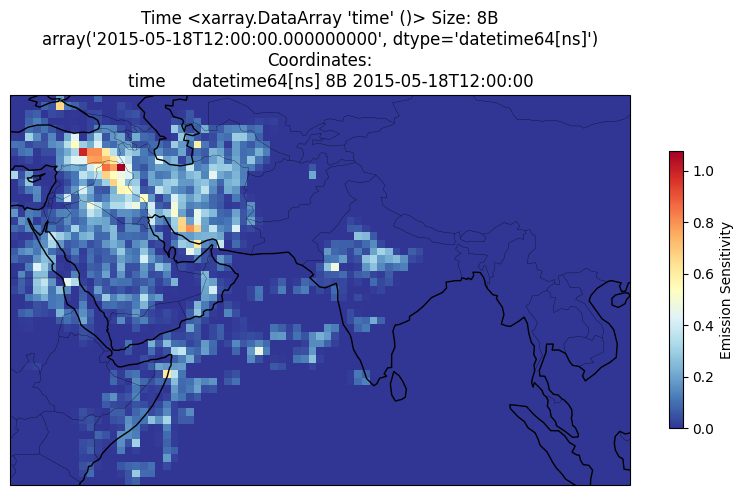

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

mesh = ax.pcolormesh(ds.longitude, ds.latitude, ds.spec001_mr.isel(time=-1, height=1).squeeze(), transform=ccrs.PlateCarree(), cmap='RdYlBu_r')

ax.set_title(f"Time {ds.time[-1].squeeze()}")
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, label='Emission Sensitivity')

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)